In [21]:
sequence = ["CMA", "LGA", "Brute Force"]
times = {
    "WikiBio": [5418.744534, 536.657125, 3982.178961],
    "WikiCounterfact": [241.114522, 225.909233, 2432.529600],
    "ZSRE": [276.387018, 170.477575, 1554.201984],
    "Counterfact": [179.560020, 150.220155, 1932.291024],
    "WikiRecent": [311.595197, 187.400229, 2190.188643],
} #these are for 10 samples

total_dataset_size = {
    "WikiBio": 30,
    "WikiCounterfact": 80,
    "ZSRE": 95,
    "Counterfact": 105,
    "WikiRecent": 120,
}

average_token_length = {
    "WikiBio": 992/10,
    "WikiCounterfact": 102/10,
    "ZSRE": 116/10,
    "Counterfact": 93/10,
    "WikiRecent": 144/10,
}

print(times)

{'WikiBio': [5418.744534, 536.657125, 3982.178961], 'WikiCounterfact': [241.114522, 225.909233, 2432.5296], 'ZSRE': [276.387018, 170.477575, 1554.201984], 'Counterfact': [179.56002, 150.220155, 1932.291024], 'WikiRecent': [311.595197, 187.400229, 2190.188643]}


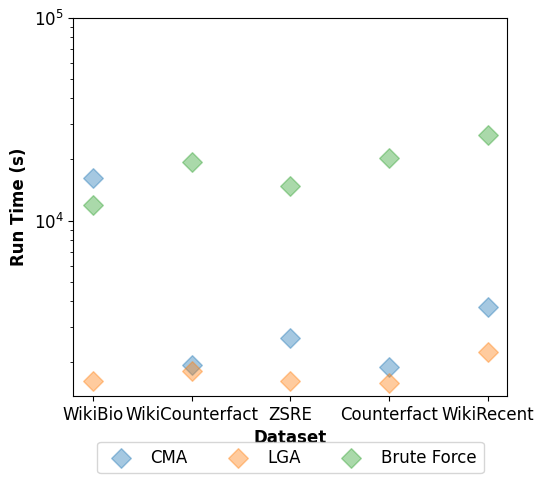

In [22]:
import matplotlib.pyplot as plt
datasets = list(times.keys())

# Scale times from 10 samples to full dataset
scaled_times = {
    d: [t * total_dataset_size[d] / 10 for t in times[d]]
    for d in datasets
}

plt.figure(figsize=(5.6, 5))  
# plt.figure()

for i, method in enumerate(sequence):
    y_vals = [scaled_times[d][i] for d in datasets]
    plt.scatter(datasets, y_vals, label=method, marker='D', alpha=0.4, s=100)

plt.xlabel("Dataset", fontweight = 'bold')
plt.ylabel("Run Time (s)", fontweight = 'bold')

plt.yscale("log")
import numpy as np
# LOG SCALE
plt.yscale("log")

# Set custom y-axis ticks manually for clarity
yticks = [1e4, 1e5]  # adjust to cover your data
plt.yticks(yticks, [f"$10^{int(np.log10(y))}$" for y in yticks])


# Legend at bottom (outside)
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


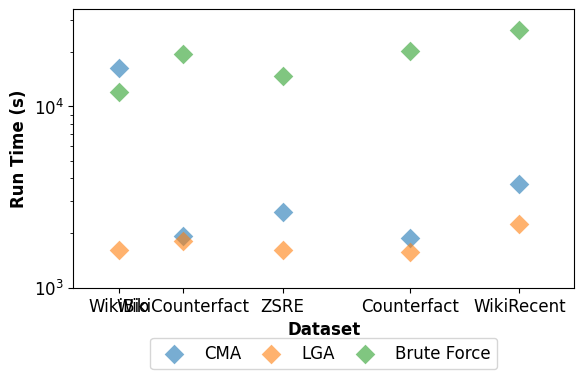

In [23]:
datasets = list(times.keys())

# Scale times from 10 samples to full dataset
scaled_times = {
    d: [t * total_dataset_size[d] / 10 for t in times[d]]
    for d in datasets
}

plt.figure(figsize=(6, 4))

# Custom x positions (numeric) for datasets
x_positions = [0, 0.7, 1.8, 3.2, 4.4]  # adjust gaps individually
# Example: space between 1&2 = 1.2-0=1.2, space between 4&5 = 5-3.2=1.8

for i, method in enumerate(sequence):
    y_vals = [scaled_times[d][i] for d in datasets]
    plt.scatter(
        x_positions,
        y_vals,
        label=method,
        marker='D',
        alpha=0.6,
        s=100,
        linewidths=0
    )

plt.xlabel("Dataset", fontweight='bold')
plt.ylabel("Run Time (s)", fontweight='bold')

plt.yscale("log")
yticks = [1e3, 1e4]
plt.yticks(yticks, [f"$10^{int(np.log10(y))}$" for y in yticks])

plt.xticks(x_positions, datasets)  # map numeric positions back to labels
plt.xlim(-0.5, len(datasets))

# Flatten all y-values across all methods
all_y_vals = []
for i in range(len(sequence)):
    for d in datasets:
        all_y_vals.append(scaled_times[d][i])
plt.ylim(1e3, max(all_y_vals)*1.3)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    columnspacing=0.8
)

plt.tight_layout()
plt.show()

{'CMA': [0.7348895922318821, 10.088689722305485, 5.623281423442254, 10.761254225745798, 7.028955080459728], 'LGA': [7.420341174078329, 10.767729887339309, 9.116753238659104, 12.863061045303807, 11.687225008673813]}


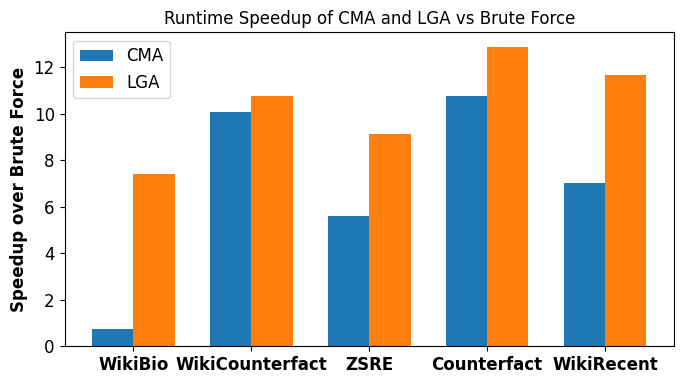

In [24]:
datasets = list(times.keys())

# Scale times from 10 samples to full dataset
scaled_times = {
    d: [t * total_dataset_size[d] / 10 for t in times[d]]
    for d in datasets
}

# Compute speedup relative to Brute Force
speedups = {
    "CMA": [],
    "LGA": []
}

for d in datasets:
    bf_time = scaled_times[d][2]
    speedups["CMA"].append(bf_time / scaled_times[d][0])
    speedups["LGA"].append(bf_time / scaled_times[d][1])
    
print(speedups)

# Plotting
x = np.arange(len(datasets))
width = 0.35

plt.figure(figsize=(7,4))
plt.bar(x - width/2, speedups["CMA"], width, label="CMA")
plt.bar(x + width/2, speedups["LGA"], width, label="LGA")

plt.xticks(x, datasets, rotation=0, fontweight='bold')
plt.ylabel("Speedup over Brute Force", fontweight='bold')
plt.title("Runtime Speedup of CMA and LGA vs Brute Force")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
plt.rcParams.update({
    "font.size": 12,        # Base font size
    "axes.titlesize": 12,   # Title font size
    "axes.labelsize": 12,   # Axis label font size
    "xtick.labelsize": 12,  # X tick labels
    "ytick.labelsize": 12,  # Y tick labels
    "legend.fontsize": 12,  # Legend text
    "figure.titlesize": 12  # Figure title (if used)
})

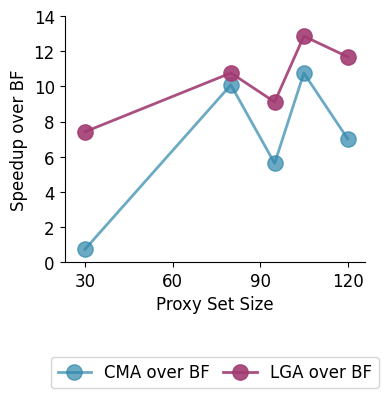

In [26]:
plt.figure(figsize=(4, 4.5))

# Custom x positions for datasets
x_positions = [total_dataset_size[d] for d in datasets]

colors = {
    "CMA": "#2e86ab",
    "LGA": "#a23b72",
}

# colors = {
#     "LGA": "tab:green",
#     "CMA": "tab:purple",
# }

alphas = {
    "CMA": 0.7,
    "LGA": 0.9,
}

for method in speedups.keys():
    y_vals = speedups[method]
    plt.plot(
        x_positions,
        y_vals,
        label=method+" over BF",
        marker='o',
        markersize=11,
        linewidth=2,
        color = colors[method],
        alpha=alphas[method]
    )

plt.xlabel("Proxy Set Size")
plt.ylabel("Speedup over BF")

plt.yscale("linear")

# sample_counts = [tok_size[d] for d in datasets]
# xtick_labels = [
#     f"{sample_counts[i]}\n{d}"
#     for i, d in enumerate(datasets)
# ]
# plt.xticks(x_positions, xtick_labels)
plt.xticks([30, 60, 90, 120], ["30", "60", "90", "120"])
plt.yticks([0, 2, 4, 6, 8, 10, 12, 14], ["0", "2", "4", "6", "8", "10", "12", "14"])

plt.xlim(23, x_positions[-1]+6)

all_y_vals = [v for vals in speedups.values() for v in vals]
plt.ylim(0, 14)

ax = plt.gca()   # get current axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.35),
    ncol=2,
    columnspacing=0.8
)

plt.tight_layout()
plt.savefig("speedup_plot_samples.png", dpi=400)  # PNG at 400 dpi
plt.show()


In [27]:
sequence = ["CMA", "LGA", "Brute Force"]
times = {
    "Counterfact": [179.560020, 150.220155, 1932.291024],
    "WikiCounterfact": [241.114522, 225.909233, 2432.529600],
    "ZSRE": [276.387018, 170.477575, 1554.201984],
    "WikiRecent": [311.595197, 187.400229, 2190.188643],
    "WikiBio": [5418.744534, 536.657125, 3982.178961],
} #these are for 10 samples

total_dataset_size = {
    "WikiBio": 30,
    "WikiCounterfact": 80,
    "ZSRE": 100,
    "Counterfact": 100,
    "WikiRecent": 120,
}

tok_size = {
    "Counterfact": 93/10,
    "WikiCounterfact": 102/10,
    "ZSRE": 116/10,
    "WikiRecent": 144/10,
    "WikiBio": (992/10)/100*19,
}

print(times)

{'Counterfact': [179.56002, 150.220155, 1932.291024], 'WikiCounterfact': [241.114522, 225.909233, 2432.5296], 'ZSRE': [276.387018, 170.477575, 1554.201984], 'WikiRecent': [311.595197, 187.400229, 2190.188643], 'WikiBio': [5418.744534, 536.657125, 3982.178961]}


In [28]:
datasets = list(times.keys())

# Scale times from 10 samples to full dataset
scaled_times = {
    d: [t * total_dataset_size[d] / 10 for t in times[d]]
    for d in datasets
}

# Compute speedup relative to Brute Force
speedups = {
    "CMA": [],
    "LGA": []
}

for d in datasets:
    bf_time = scaled_times[d][2]
    speedups["CMA"].append(bf_time / scaled_times[d][0])
    speedups["LGA"].append(bf_time / scaled_times[d][1])

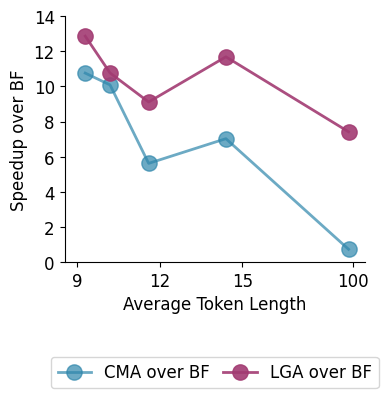

In [29]:
plt.figure(figsize=(4, 4.5))

# Custom x positions for datasets
# x_positions = [0, 0.325, 0.625, 0.875, 1.2]
x_positions = [tok_size[d] for d in datasets]

colors = {
    "CMA": "#2e86ab",
    "LGA": "#a23b72",
}

# colors = {
#     "LGA": "tab:green",
#     "CMA": "tab:purple",
# }

alphas = {
    "CMA": 0.7,
    "LGA": 0.9,
}

for method in speedups.keys():
    y_vals = speedups[method]
    plt.plot(
        x_positions,
        y_vals,
        label=method+" over BF",
        marker='o',
        markersize=11,
        linewidth=2,
        color = colors[method],
        alpha=alphas[method]
    )

plt.xlabel("Average Token Length")
plt.ylabel("Speedup over BF")

plt.yscale("linear")

# sample_counts = [tok_size[d] for d in datasets]
# xtick_labels = [
#     f"{sample_counts[i]}\n{d}"
#     for i, d in enumerate(datasets)
# ]
# plt.xticks(x_positions, xtick_labels)
plt.xticks([9, 12, 15, 19], ["9", "12", "15", "100"])
plt.yticks([0, 2, 4, 6, 8, 10, 12, 14], ["0", "2", "4", "6", "8", "10", "12", "14"])

plt.xticks()

plt.xlim(8.55, x_positions[-1]+.6)

all_y_vals = [v for vals in speedups.values() for v in vals]
plt.ylim(0, 14)

ax = plt.gca()   # get current axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.35),
    ncol=2,
    columnspacing=0.8
)

plt.tight_layout()
plt.savefig("speedup_plot_sample.png", dpi=400)  # PNG at 400 dpi
plt.show()
